# Module 3 Project – PCA + Classification on MNIST

**Problem statement:** Perform an analysis of PCA on each classification method. *How do the principal components impact classification performance?*

**Approach**
1. Use the same data, the same stratified 80:20 split (`random_state=42`) and the same models and hyperparameters as `M3_Code.ipynb`.
2. Fit PCA on the **training set only**, then project both train and test images onto the first *k* principal components.
3. Train every model on *k* = 10, 20, 50, 100 and 200 components, plus the original 784 raw pixels as the baseline.
4. Compare test accuracy, macro F1, over-fitting (train − test accuracy) and training/prediction time as *k* changes, for each method.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

RANDOM_STATE = 42

## Step 1 – Load the data

In [3]:
mnist = pd.read_csv('G:/Python/AIML-TimesPro/Projects/Module 3/mnist_train.csv')
mnist.shape

(42000, 785)

## Step 2 – Features, scaling and the 80:20 split

The same preprocessing as before: pixels are divided by 255 so they lie in [0, 1], and `stratify=y` keeps the digit proportions equal in train and test.

In [4]:
X_scaled = mnist.drop(columns=['label']).values.astype(np.float32) / 255.0
y = mnist['label'].values

train_X, test_X, train_y, test_y = train_test_split(X_scaled,
                                                    y,
                                                    test_size=0.2,
                                                    stratify=y,
                                                    random_state=RANDOM_STATE)

N_PIXELS = train_X.shape[1]
print(f' Train X Shape : {train_X.shape},\n Test X Shape : {test_X.shape}')

 Train X Shape : (33600, 784),
 Test X Shape : (8400, 784)


## Step 3 – Principal Component Analysis

**Why PCA?** Neighbouring pixels are strongly correlated, and the pixels around the border are almost always 0, so most of the 784 dimensions are redundant. PCA finds orthogonal directions (principal components) ordered by how much variance they explain. Keeping only the first *k* gives a compact representation of each image.

**Design choices**
* **Fit on the training set only.** The PCA mean and components are learned from `train_X` and then applied to `test_X`, so no information from the test set leaks into the features.
* **No standardisation before PCA.** All pixels already share the same [0, 1] scale. Standardising would inflate the near-constant border pixels, which are mostly noise, and give them as much weight as the informative centre pixels.
* **One fit for all *k*.** The first *k* components of a full PCA are exactly the components that `PCA(n_components=k)` would find, so we fit once and slice the columns.

### 3.1 Explained variance

In [5]:
t0 = time.time()
pca = PCA(random_state=RANDOM_STATE).fit(train_X)
pca_fit_time = time.time() - t0

explained = pca.explained_variance_ratio_
cum_var = np.cumsum(explained)
print(f'PCA fit on {train_X.shape[0]} x {N_PIXELS} training matrix: {pca_fit_time:.1f}s')

thresholds = [0.70, 0.80, 0.90, 0.95, 0.99]
pd.DataFrame({'Variance explained': [f'{t:.0%}' for t in thresholds],
              'Components needed': [int(np.searchsorted(cum_var, t) + 1) for t in thresholds],
              '% of 784 pixels': [f'{(np.searchsorted(cum_var, t) + 1) / N_PIXELS:.1%}' for t in thresholds]})

PCA fit on 33600 x 784 training matrix: 0.5s


,Variance explained,Components needed,% of 784 pixels
0,70%,26,3.3%
1,80%,43,5.5%
2,90%,87,11.1%
3,95%,153,19.5%
4,99%,330,42.1%


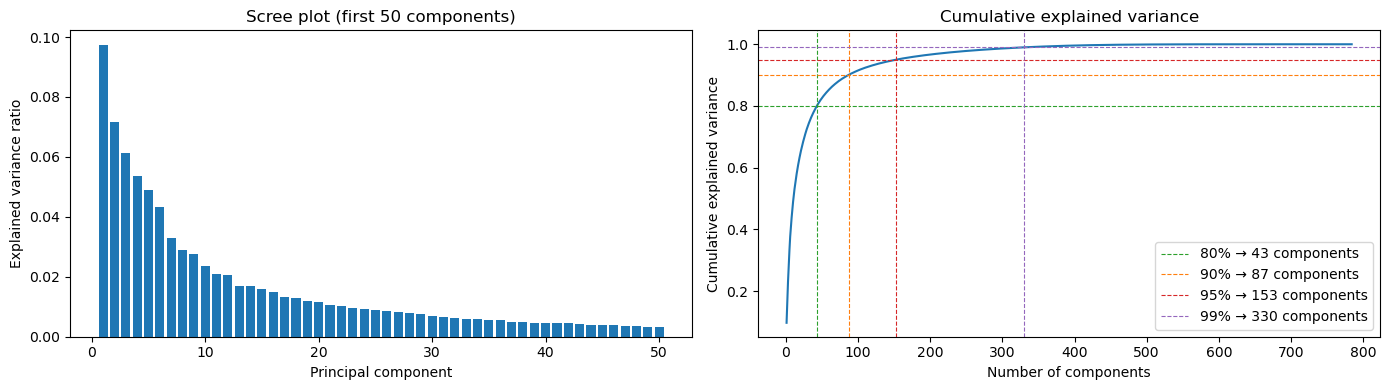

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(range(1, 51), explained[:50])
axes[0].set_xlabel('Principal component'); axes[0].set_ylabel('Explained variance ratio')
axes[0].set_title('Scree plot (first 50 components)')

axes[1].plot(range(1, N_PIXELS + 1), cum_var)
for t, c in zip([0.80, 0.90, 0.95, 0.99], ['tab:green', 'tab:orange', 'tab:red', 'tab:purple']):
    k = np.searchsorted(cum_var, t) + 1
    axes[1].axhline(t, ls='--', lw=0.8, color=c)
    axes[1].axvline(k, ls='--', lw=0.8, color=c, label=f'{t:.0%} → {k} components')
axes[1].set_xlabel('Number of components'); axes[1].set_ylabel('Cumulative explained variance')
axes[1].set_title('Cumulative explained variance'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

### 3.2 Reconstruction with *k* components
Projecting onto *k* components and mapping back to pixel space shows how much of each image survives the compression.

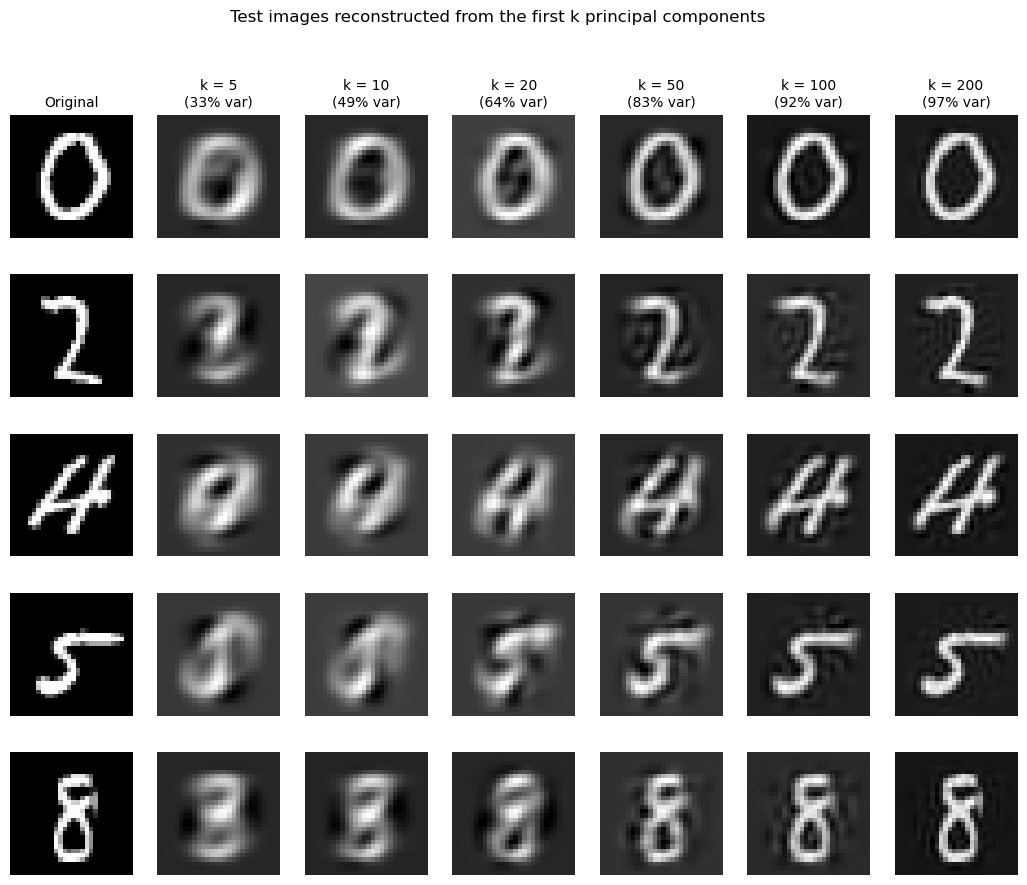

In [9]:
K_SHOW = [5, 10, 20, 50, 100, 200]
samples = [np.where(test_y == d)[0][0] for d in [0, 2, 4, 5, 8]]
Z_test_full = pca.transform(test_X[samples])

fig, axes = plt.subplots(len(samples), len(K_SHOW) + 1, figsize=(13, 10))
for r, idx in enumerate(samples):
    axes[r, 0].imshow(test_X[idx].reshape(28, 28), cmap='gray')
    axes[r, 0].set_title('Original' if r == 0 else '', fontsize=10)
    for c, k in enumerate(K_SHOW, start=1):
        recon = Z_test_full[r, :k] @ pca.components_[:k] + pca.mean_
        axes[r, c].imshow(recon.reshape(28, 28), cmap='gray')
        if r == 0:
            axes[r, c].set_title(f'k = {k}\n({cum_var[k-1]:.0%} var)', fontsize=10)
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('Test images reconstructed from the first k principal components'); plt.show()

### 3.5 Project train and test sets
Both sets are transformed once. `get_features(k)` then returns the first *k* columns, or the raw pixels when *k* = 784 (the no-PCA baseline).

In [22]:
t0 = time.time()
train_pca = pca.transform(train_X)
test_pca = pca.transform(test_X)
print(f'Transform time (train + test): {time.time() - t0:.2f}s')

K_LIST = [10, 20, 50, 100, 200, 350]

def get_features(k):
    if k == N_PIXELS:
        return train_X, test_X
    return train_pca[:, :k], test_pca[:, :k]

for k in K_LIST:
    label = 'raw pixels (baseline)' if k == N_PIXELS else f'{cum_var[k-1]:.1%} of variance'
    print(f'k = {k:>3}: {label}')

Transform time (train + test): 0.26s
k =  10: 48.9% of variance
k =  20: 64.5% of variance
k =  50: 82.6% of variance
k = 100: 91.5% of variance
k = 200: 96.7% of variance
k = 350: 99.2% of variance


## Step 4 – A common evaluation helper

This is the same helper as before, with two changes:
* **`results` is a list with one row per (model, *k*)**, because every model is now trained several times.
* **Train accuracy is measured on a fixed stratified sample of 8,400 training images.** Predicting on all 33,600 training images costs several minutes per run for the SVMs. A sample the same size as the test set gives the same over-fitting signal at a quarter of the cost.

`fit_time` covers model training only. PCA itself is a one-off cost, reported in Step 3.

In [23]:
_, train_eval_idx = train_test_split(np.arange(len(train_y)), test_size=len(test_y),
                                     stratify=train_y, random_state=RANDOM_STATE)

results = []
predictions = {}

def record(name, k, train_pred, test_pred, fit_time, pred_time):
    train_accuracy = accuracy_score(train_y[train_eval_idx], train_pred)
    test_accuracy = accuracy_score(test_y, test_pred)
    p, r, f1, _ = precision_recall_fscore_support(test_y, test_pred, average='macro')

    results.append({'model': name, 'n_components': k, 'variance_kept': cum_var[k - 1],
                    'train_acc': train_accuracy, 'test_acc': test_accuracy,
                    'precision': p, 'recall': r, 'f1': f1,
                    'fit_time': fit_time, 'pred_time': pred_time})
    predictions[(name, k)] = test_pred
    k_label = 'raw' if k == N_PIXELS else k
    print(f'{name:<24} k = {k_label:>3} | train acc = {train_accuracy:.4f} | test acc = {test_accuracy:.4f} | '
          f'F1 = {f1:.4f} | fit = {fit_time:6.1f}s | predict = {pred_time:5.2f}s')

def evaluate_model(name, make_model, k):
    Xtr, Xte = get_features(k)
    model = make_model()

    t0 = time.time()
    model.fit(Xtr, train_y)
    fit_time = time.time() - t0

    t0 = time.time()
    y_pred = model.predict(Xte)
    pred_time = time.time() - t0

    record(name, k, model.predict(Xtr[train_eval_idx]), y_pred, fit_time, pred_time)
    return model

def evaluate_over_k(name, make_model, k_list=K_LIST):
    for k in k_list:
        evaluate_model(name, make_model, k)

## Step 5 – Train every method on each number of components

Each model uses the same hyperparameters as in `M3_Code_Self.ipynb`, so the only thing that changes is the input features. `make_model` is a function (a `lambda`) so that a fresh, untrained model is built for every *k*.

> **Runtime:** roughly 20–30 minutes on an 8-core CPU in total. Most of it is the raw-pixel baseline for Bagging, gradient boosting, XGBoost and the SVMs.

### 5.1 Logistic Regression

In [24]:
evaluate_over_k('Logistic Regression',
                lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

Logistic Regression      k =  10 | train acc = 0.7971 | test acc = 0.8002 | F1 = 0.7966 | fit =    0.7s | predict =  0.00s
Logistic Regression      k =  20 | train acc = 0.8717 | test acc = 0.8731 | F1 = 0.8713 | fit =    0.9s | predict =  0.00s
Logistic Regression      k =  50 | train acc = 0.9070 | test acc = 0.9067 | F1 = 0.9052 | fit =    0.9s | predict =  0.00s
Logistic Regression      k = 100 | train acc = 0.9200 | test acc = 0.9139 | F1 = 0.9125 | fit =    1.1s | predict =  0.01s
Logistic Regression      k = 200 | train acc = 0.9290 | test acc = 0.9145 | F1 = 0.9133 | fit =    1.5s | predict =  0.01s
Logistic Regression      k = 350 | train acc = 0.9365 | test acc = 0.9129 | F1 = 0.9117 | fit =    2.6s | predict =  0.03s


### 5.2 Decision Tree

In [25]:
evaluate_over_k('Decision Tree',
                lambda: DecisionTreeClassifier(random_state=RANDOM_STATE))

Decision Tree            k =  10 | train acc = 1.0000 | test acc = 0.8181 | F1 = 0.8157 | fit =    1.4s | predict =  0.00s
Decision Tree            k =  20 | train acc = 1.0000 | test acc = 0.8364 | F1 = 0.8345 | fit =    3.1s | predict =  0.00s
Decision Tree            k =  50 | train acc = 1.0000 | test acc = 0.8339 | F1 = 0.8318 | fit =    9.2s | predict =  0.01s
Decision Tree            k = 100 | train acc = 1.0000 | test acc = 0.8281 | F1 = 0.8259 | fit =   20.0s | predict =  0.00s
Decision Tree            k = 200 | train acc = 1.0000 | test acc = 0.8182 | F1 = 0.8159 | fit =   39.8s | predict =  0.01s
Decision Tree            k = 350 | train acc = 1.0000 | test acc = 0.8115 | F1 = 0.8093 | fit =   71.3s | predict =  0.01s


### 5.3 Bagging

In [26]:
evaluate_over_k('Bagging Classifier',
                lambda: BaggingClassifier(n_estimators=50, n_jobs=-1, random_state=RANDOM_STATE))

Bagging Classifier       k =  10 | train acc = 0.9998 | test acc = 0.8938 | F1 = 0.8923 | fit =   25.6s | predict =  0.35s
Bagging Classifier       k =  20 | train acc = 0.9999 | test acc = 0.9213 | F1 = 0.9203 | fit =   17.8s | predict =  0.28s
Bagging Classifier       k =  50 | train acc = 1.0000 | test acc = 0.9246 | F1 = 0.9236 | fit =   42.8s | predict =  0.29s
Bagging Classifier       k = 100 | train acc = 1.0000 | test acc = 0.9192 | F1 = 0.9182 | fit =   87.1s | predict =  0.30s
Bagging Classifier       k = 200 | train acc = 1.0000 | test acc = 0.9125 | F1 = 0.9114 | fit =  178.1s | predict =  0.35s
Bagging Classifier       k = 350 | train acc = 1.0000 | test acc = 0.9089 | F1 = 0.9078 | fit =  362.9s | predict =  0.68s


### 5.4 Random Forest
Each split considers √k random features. With PCA, that means √k components instead of √784 ≈ 28 pixels.

In [27]:
evaluate_over_k('RandomForest Classifier',
                lambda: RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE))

RandomForest Classifier  k =  10 | train acc = 1.0000 | test acc = 0.9088 | F1 = 0.9075 | fit =    5.0s | predict =  0.11s
RandomForest Classifier  k =  20 | train acc = 1.0000 | test acc = 0.9444 | F1 = 0.9438 | fit =    6.2s | predict =  0.10s
RandomForest Classifier  k =  50 | train acc = 1.0000 | test acc = 0.9474 | F1 = 0.9467 | fit =   10.7s | predict =  0.11s
RandomForest Classifier  k = 100 | train acc = 1.0000 | test acc = 0.9477 | F1 = 0.9471 | fit =   14.9s | predict =  0.20s
RandomForest Classifier  k = 200 | train acc = 1.0000 | test acc = 0.9415 | F1 = 0.9407 | fit =   22.5s | predict =  0.11s
RandomForest Classifier  k = 350 | train acc = 1.0000 | test acc = 0.9307 | F1 = 0.9297 | fit =   27.1s | predict =  0.11s


### 5.5 Gradient Boosting (histogram)

In [28]:
evaluate_over_k('HistGradientBoosting',
                lambda: HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200,
                                                       early_stopping=True,
                                                       random_state=RANDOM_STATE))

HistGradientBoosting     k =  10 | train acc = 0.9919 | test acc = 0.9206 | F1 = 0.9196 | fit =   18.0s | predict =  0.62s
HistGradientBoosting     k =  20 | train acc = 0.9951 | test acc = 0.9545 | F1 = 0.9541 | fit =   29.4s | predict =  0.61s
HistGradientBoosting     k =  50 | train acc = 0.9957 | test acc = 0.9614 | F1 = 0.9610 | fit =   20.4s | predict =  0.83s
HistGradientBoosting     k = 100 | train acc = 0.9954 | test acc = 0.9636 | F1 = 0.9632 | fit =   36.9s | predict =  1.34s
HistGradientBoosting     k = 200 | train acc = 0.9956 | test acc = 0.9620 | F1 = 0.9617 | fit =  132.2s | predict =  1.96s
HistGradientBoosting     k = 350 | train acc = 0.9951 | test acc = 0.9617 | F1 = 0.9613 | fit =   86.8s | predict =  1.53s


### 5.6 XGBoost

In [29]:
evaluate_over_k('XGBoost',
                lambda: XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                      subsample=0.8, colsample_bytree=0.5,
                                      tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE))

XGBoost                  k =  10 | train acc = 0.9967 | test acc = 0.9195 | F1 = 0.9186 | fit =    5.5s | predict =  0.05s
XGBoost                  k =  20 | train acc = 1.0000 | test acc = 0.9592 | F1 = 0.9587 | fit =    7.4s | predict =  0.09s
XGBoost                  k =  50 | train acc = 1.0000 | test acc = 0.9644 | F1 = 0.9640 | fit =   16.9s | predict =  0.09s
XGBoost                  k = 100 | train acc = 1.0000 | test acc = 0.9642 | F1 = 0.9638 | fit =   28.5s | predict =  0.09s
XGBoost                  k = 200 | train acc = 1.0000 | test acc = 0.9598 | F1 = 0.9594 | fit =   52.6s | predict =  0.09s
XGBoost                  k = 350 | train acc = 1.0000 | test acc = 0.9600 | F1 = 0.9596 | fit =  102.1s | predict =  0.10s


### 5.7 Support Vector Machine (RBF and polynomial kernels)

In [30]:
evaluate_over_k('SVM (RBF)',
                lambda: SVC(kernel='rbf', C=10, gamma='scale', random_state=RANDOM_STATE))

SVM (RBF)                k =  10 | train acc = 0.9648 | test acc = 0.9412 | F1 = 0.9404 | fit =    4.0s | predict =  3.58s
SVM (RBF)                k =  20 | train acc = 0.9958 | test acc = 0.9763 | F1 = 0.9760 | fit =    3.0s | predict =  2.65s
SVM (RBF)                k =  50 | train acc = 0.9998 | test acc = 0.9839 | F1 = 0.9837 | fit =    5.4s | predict =  3.72s
SVM (RBF)                k = 100 | train acc = 0.9999 | test acc = 0.9817 | F1 = 0.9814 | fit =    9.6s | predict =  5.46s
SVM (RBF)                k = 200 | train acc = 1.0000 | test acc = 0.9820 | F1 = 0.9818 | fit =   22.4s | predict = 10.25s
SVM (RBF)                k = 350 | train acc = 1.0000 | test acc = 0.9810 | F1 = 0.9807 | fit =   37.3s | predict = 19.57s


In [31]:
evaluate_over_k('SVM (Poly)',
                lambda: SVC(kernel='poly', C=10, gamma='scale', random_state=RANDOM_STATE))

SVM (Poly)               k =  10 | train acc = 0.9479 | test acc = 0.9282 | F1 = 0.9272 | fit =    3.7s | predict =  1.03s
SVM (Poly)               k =  20 | train acc = 0.9951 | test acc = 0.9726 | F1 = 0.9722 | fit =    2.9s | predict =  0.83s
SVM (Poly)               k =  50 | train acc = 0.9999 | test acc = 0.9810 | F1 = 0.9806 | fit =    6.6s | predict =  1.36s
SVM (Poly)               k = 100 | train acc = 1.0000 | test acc = 0.9815 | F1 = 0.9812 | fit =   13.6s | predict =  2.37s
SVM (Poly)               k = 200 | train acc = 1.0000 | test acc = 0.9811 | F1 = 0.9808 | fit =   31.4s | predict =  5.46s
SVM (Poly)               k = 350 | train acc = 1.0000 | test acc = 0.9815 | F1 = 0.9813 | fit =   61.2s | predict = 13.30s


### 5.8 Artificial Neural Network (PyTorch)
This is the same MLP as before (hidden layers 256 → 128, ReLU, BatchNorm, dropout 0.3, Adam, 25 epochs). Only the input layer changes size: it has *k* inputs instead of 784.

In [32]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class MNISTModel(nn.Module):

    def __init__(self, n_in, out_sz, layers, p=0.3):
        super().__init__()

        layerlist = []
        for i in layers:
            layerlist.append(nn.Linear(n_in, i))
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i
        layerlist.append(nn.Linear(n_in, out_sz))

        self.layers = nn.Sequential(*layerlist)

    def forward(self, x):
        return self.layers(x)


def evaluate_ann(k, epochs=25):
    torch.manual_seed(RANDOM_STATE)
    Xtr, Xte = get_features(k)
    X_train_t = torch.tensor(Xtr, dtype=torch.float32)
    X_test_t = torch.tensor(Xte, dtype=torch.float32)
    y_train_t = torch.tensor(train_y, dtype=torch.long)
    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=128, shuffle=True)

    model = MNISTModel(n_in=k, out_sz=10, layers=[256, 128], p=0.3).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            loss = criterion(model(X_batch), y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    fit_time = time.time() - t0

    model.eval()
    with torch.no_grad():
        t0 = time.time()
        test_pred = model(X_test_t.to(device)).argmax(dim=1).cpu().numpy()
        pred_time = time.time() - t0
        train_pred = model(X_train_t[train_eval_idx].to(device)).argmax(dim=1).cpu().numpy()

    record('ANN (PyTorch)', k, train_pred, test_pred, fit_time, pred_time)
    return model

for k in K_LIST:
    evaluate_ann(k)

ANN (PyTorch)            k =  10 | train acc = 0.9505 | test acc = 0.9404 | F1 = 0.9396 | fit =   27.8s | predict =  0.02s
ANN (PyTorch)            k =  20 | train acc = 0.9895 | test acc = 0.9755 | F1 = 0.9752 | fit =   31.5s | predict =  0.01s
ANN (PyTorch)            k =  50 | train acc = 0.9985 | test acc = 0.9817 | F1 = 0.9815 | fit =   27.5s | predict =  0.01s
ANN (PyTorch)            k = 100 | train acc = 0.9989 | test acc = 0.9802 | F1 = 0.9800 | fit =   32.4s | predict =  0.02s
ANN (PyTorch)            k = 200 | train acc = 0.9998 | test acc = 0.9776 | F1 = 0.9774 | fit =   43.0s | predict =  0.02s
ANN (PyTorch)            k = 350 | train acc = 0.9999 | test acc = 0.9726 | F1 = 0.9723 | fit =   45.6s | predict =  0.01s


## Step 6 – How the number of components affects each method

### 6.1 Results table

In [33]:
results_df = pd.DataFrame(results)
results_df['overfit_gap'] = results_df['train_acc'] - results_df['test_acc']

MODEL_ORDER = results_df.groupby('model')['test_acc'].max().sort_values(ascending=False).index.tolist()
K_LABELS = {k: ('784 (raw)' if k == N_PIXELS else str(k)) for k in K_LIST}

(results_df.set_index(['model', 'n_components'])
           .loc[MODEL_ORDER]
           .style.format({'variance_kept': '{:.1%}', 'train_acc': '{:.4f}', 'test_acc': '{:.4f}',
                          'precision': '{:.4f}', 'recall': '{:.4f}', 'f1': '{:.4f}',
                          'overfit_gap': '{:.4f}', 'fit_time': '{:.1f}', 'pred_time': '{:.2f}'})
           .background_gradient(subset=['test_acc'], cmap='Greens'))

### 6.2 Test accuracy by model and number of components
The best *k* for each model is outlined in black.

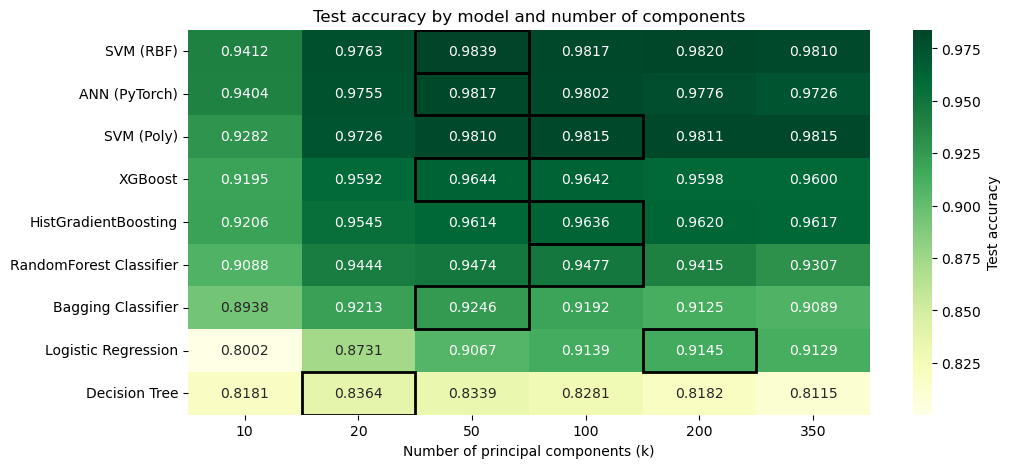

In [34]:
acc_pivot = (results_df.pivot(index='model', columns='n_components', values='test_acc')
                       .loc[MODEL_ORDER, K_LIST].rename(columns=K_LABELS))

plt.figure(figsize=(11, 5))
ax = sns.heatmap(acc_pivot, annot=True, fmt='.4f', cmap='YlGn', cbar_kws={'label': 'Test accuracy'})
for r, row in enumerate(acc_pivot.values):
    c = int(np.nanargmax(row))
    ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor='black', lw=2))
plt.xlabel('Number of principal components (k)'); plt.ylabel('')
plt.title('Test accuracy by model and number of components'); plt.show()

### 6.3 All methods on one chart

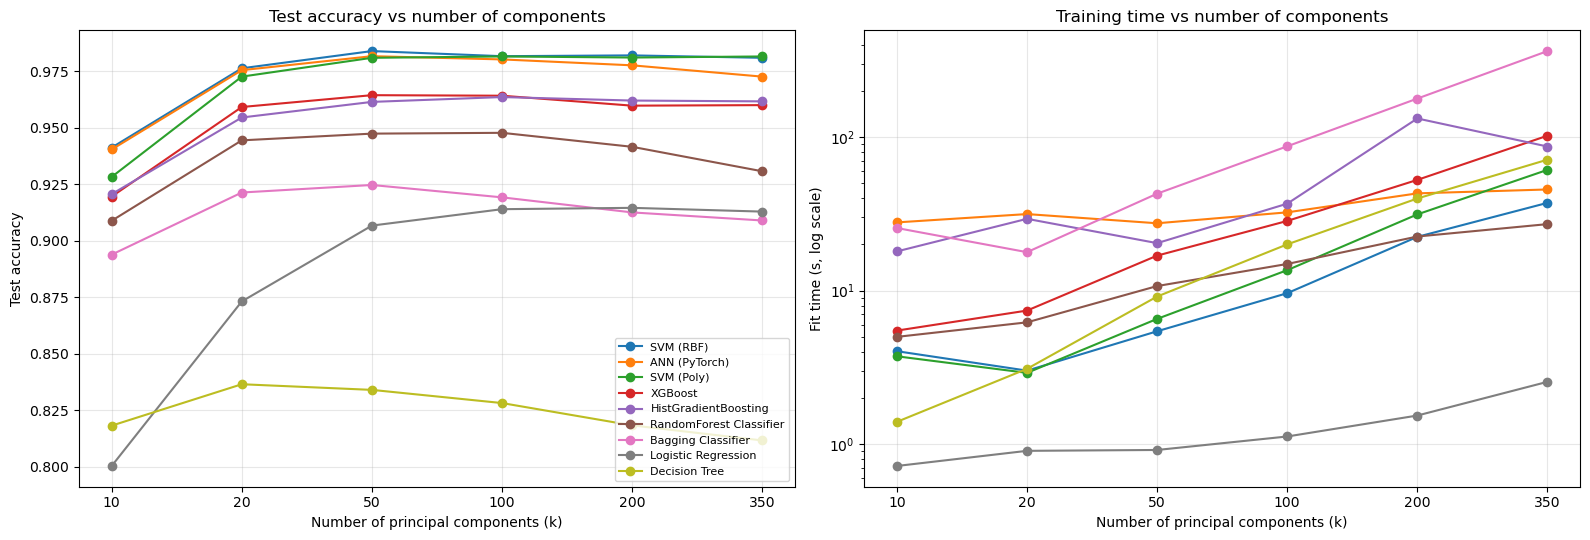

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for name in MODEL_ORDER:
    d = results_df[results_df.model == name].set_index('n_components').loc[K_LIST]
    axes[0].plot(x, d['test_acc'], 'o-', label=name)
    axes[1].plot(x, d['fit_time'], 'o-', label=name)

axes[0].set_ylabel('Test accuracy'); axes[0].set_title('Test accuracy vs number of components')
axes[1].set_ylabel('Fit time (s, log scale)'); axes[1].set_yscale('log')
axes[1].set_title('Training time vs number of components')
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels([K_LABELS[k] for k in K_LIST])
    ax.set_xlabel('Number of principal components (k)'); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

### 6.4 Over-fitting vs number of components
The train − test accuracy gap. A smaller gap means the model generalises better.

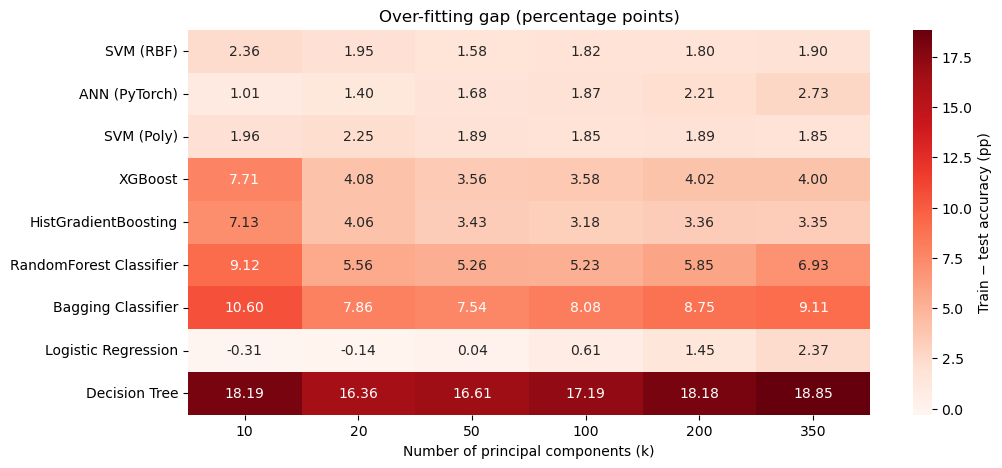

In [38]:
gap_pivot = (results_df.pivot(index='model', columns='n_components', values='overfit_gap')
                       .loc[MODEL_ORDER, K_LIST].rename(columns=K_LABELS)) * 100

plt.figure(figsize=(11, 5))
sns.heatmap(gap_pivot, annot=True, fmt='.2f', cmap='Reds', cbar_kws={'label': 'Train − test accuracy (pp)'})
plt.xlabel('Number of principal components (k)'); plt.ylabel('')
plt.title('Over-fitting gap (percentage points)'); plt.show()

## Step 7 – Observations

*(Written after running the notebook. See the discussion below.)*